# Chapter 1 - Exploratory Data Analysis

**Practical Statistics for Data Scientists, 2nd ed.** - Peter Bruce, Andrew Bruce, and Peter Gedeck

This self-contained notebook reproduces the *learning workflow* of Chapter 1 with original synthetic data and independently written code. EDA makes data understandable before modeling: examine structure, describe center and variability, inspect distributions, and look for relationships.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
rng = np.random.default_rng(42)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

## 1. Rectangular data and data quality

Rectangular data is the general term for two-dimensional matrix that has rows indicating records and columns indicating features such as variables.

A data frame is **rectangular data**: each row is a record and each column is a feature. An identifier is useful for joins but its mean is meaningless. A real project may also use nonrectangular arrays, graphs, text, or images. Start by checking types, missingness, and plausibility.

Key terms for **Rectangular data**
- Data frame: Rectangular data (like spreadsheet) is a basic data structure for statistic and Machine Learning models
- Feature: Column within a table referred to as a feature
- Outcome: Predicting an outcome which are often a yes/no outcome.The features are sometime used to predict the outcome
- Records: A row within a table is commonly referred as a record

In [2]:
n = 600
customers = pd.DataFrame({
    "customer_id": np.arange(1001, 1001+n),
    "region": rng.choice(["West", "Central", "East"], n, p=[.32, .36, .32]),
    "channel": rng.choice(["web", "mobile", "store"], n, p=[.45, .35, .20]),
    "tenure_months": rng.integers(1, 61, n),
    "visits": rng.poisson(7, n),
})
customers["spend"] = np.round(np.exp(rng.normal(3.8, .55, n)) + 2.2*customers.visits, 2)
customers.loc[rng.choice(n, 9, replace=False), "spend"] = np.nan
display(customers.head())
print(customers.dtypes)
print("\nMissing values:\n", customers.isna().sum())

,customer_id,region,channel,tenure_months,visits,spend
0,1001,East,mobile,1,10,103.91
1,1002,Central,mobile,34,7,48.97
2,1003,East,store,45,7,43.09
3,1004,East,mobile,34,4,57.49
4,1005,West,store,24,9,78.62


customer_id        int64
region            object
channel           object
tenure_months      int64
visits             int64
spend            float64
dtype: object

Missing values:
 customer_id      0
region           0
channel          0
tenure_months    0
visits           0
spend            9
dtype: int64


## 2. Location and variability

The **mean** uses every value but moves with outliers. The **median** is the middle ordered value and is robust. A **trimmed mean** removes equal tails; a **weighted mean** gives records unequal importance. Standard deviation measures squared-deviation spread, while IQR and MAD are robust spread measures. Percentiles communicate a distribution's position directly.

Other terms for **Estimates of Location**
- Robust: Not sensitive to extremes value.
- Outlier: A data value that is far different from the normal or most data which makes them an outcast basically.
- Percentile: Value such that P percent of the data lies below, like top 20% and stuff.


In [ ]:
from scipy import stats
spend = customers.spend.dropna()
q1, q3 = spend.quantile([.25, .75])
summary = pd.Series({
    "mean": spend.mean(), "median": spend.median(),
    "10% trimmed mean": stats.trim_mean(spend, .10),
    "visit-weighted mean": np.average(spend, weights=customers.loc[spend.index, "visits"]+1),
    "sample standard deviation": spend.std(ddof=1), "IQR": q3-q1,
    "MAD": stats.median_abs_deviation(spend, scale=1),
    "5th percentile": spend.quantile(.05), "95th percentile": spend.quantile(.95),
})
summary.to_frame("spend")

,spend
mean,68.191
median,59.510
10% trimmed mean,64.051
visit-weighted mean,69.336
sample standard deviation,31.435
IQR,35.355
MAD,16.170
5th percentile,32.100
95th percentile,129.275


## 3. Distributions

A histogram groups values into bins, so its look depends on bin width. A density curve smooths the observed distribution and is an estimate, not raw data. A boxplot shows the median, quartiles, and possible outliers (usually beyond 1.5 IQR). Use several views rather than relying on one summary number.

Key terms for Exploring the **Distribution**
- Boxplot: A plot to visualize the distributions of data.
- Frequency Table: Tally of the count of numeric data values that fall into a set of intervals
- Histogram: Plot frequency table with the bins on the x-axis and the count on the y-axis, which is visually similar to the bar chart but it is a different thing as Bar charts shows the frequency or proportion for each category plotted as bars. So histogram basically shows the data correlating whilst the bar chart shows its x-axis different categories of a factor variable.
- Density plot: A smoothed version of the histogram, basically made it into a line and is often based on a kernel density estimate.

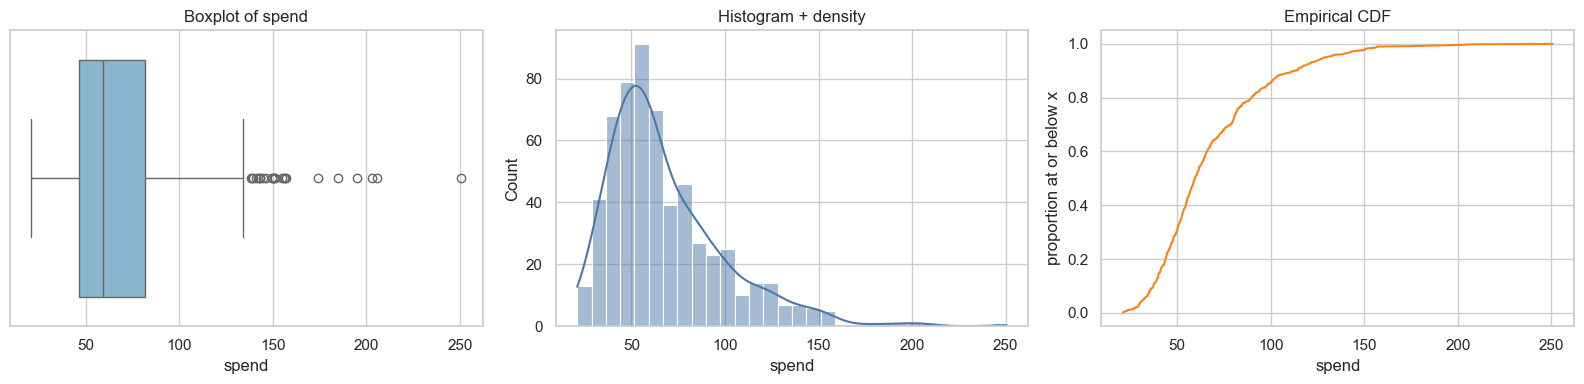

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x=spend, color="#7db8da", ax=axes[0]); axes[0].set_title("Boxplot of spend")
sns.histplot(spend, bins=30, kde=True, color="#4c78a8", ax=axes[1]); axes[1].set_title("Histogram + density")
axes[2].plot(np.sort(spend), np.linspace(0, 1, len(spend)), color="#f58518")
axes[2].set(title="Empirical CDF", xlabel="spend", ylabel="proportion at or below x")
plt.tight_layout()

## 4. Categorical data, correlation, and multiple variables

For categorical features, report counts and proportions. The **mode** is the most common level. For a binary event, its sample proportion estimates probability; an expected value is a probability-weighted long-run average. Pearson correlation measures linear association, not causality. Plot relationships to identify nonlinearity, subgroups, or overplotting.

Key terms for Exploring **Categorical data**
- Expected value: When the categories can be associated with a numeric value, this gives an average value based on a category's probability of occurrence.
- Bar Charts: The frequency or proportion for each category plotted as bars.
- Pie Charts: The frequency or proportion for each category as plotted as wedges in a pie, hence the name as pie chart.

Key terms for Exploring **Correlation**
- Correlation coefficient: Metric that measures the extent which numeric variables are associated with one another (ranges from -1 to +1)
- Correlation matrix: Table where variables are shown on both rows and columns and the cell values are the correlations between the variables.
- Scatterplot: A plot in which the x-axis is the value of one variable, and the y-axis the value of another.


,count,proportion
channel,,
web,273,0.455
mobile,201,0.335
store,126,0.210


Mode: web
P(purchase): 0.285


,tenure_months,visits,spend
tenure_months,1.000,-0.017,-0.100
visits,-0.017,1.000,0.112
spend,-0.100,0.112,1.000


count   mean  median    std
region  channel                             
Central mobile      69  68.19   57.30  32.35
        store       45  65.80   56.61  29.39
        web         93  71.37   61.30  32.67
East    mobile      63  75.54   65.45  37.05
        store       38  64.48   57.18  25.41
        web         83  69.58   60.87  35.03
West    mobile      65  65.22   63.10  23.76
        store       41  65.61   57.58  35.33
        web         94  64.72   58.96  27.96

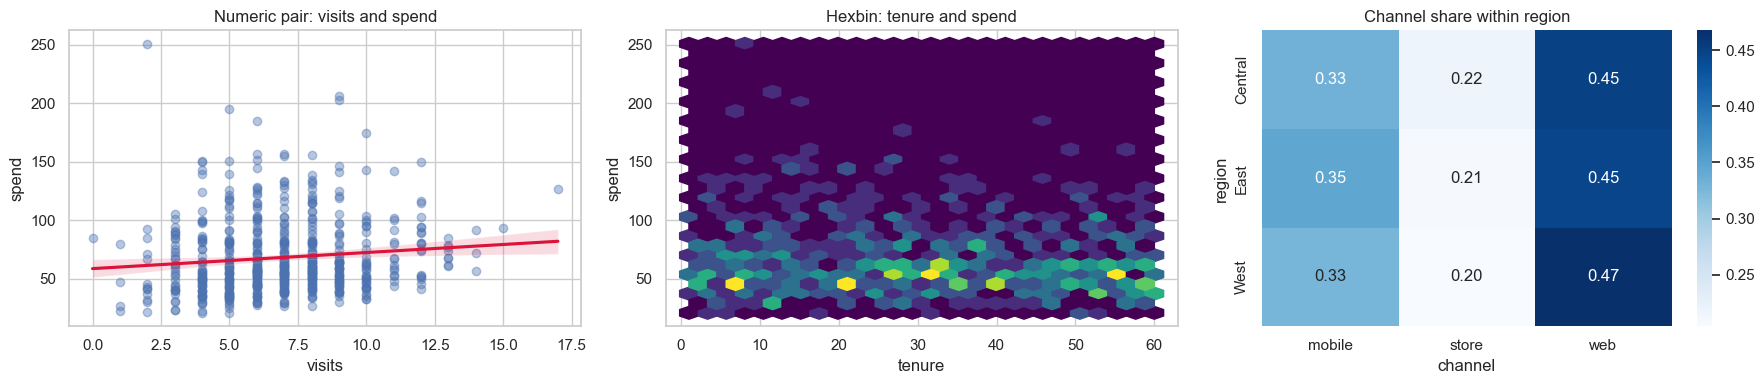

In [5]:
customers["purchased"] = rng.binomial(1, np.where(customers.channel.eq("mobile"), .34, .27))
channel_counts = customers.channel.value_counts()
display(pd.DataFrame({"count": channel_counts, "proportion": channel_counts/len(customers)}))
print("Mode:", customers.channel.mode()[0])
print("P(purchase):", round(customers.purchased.mean(), 3))
numeric = customers[["tenure_months", "visits", "spend"]].dropna()
display(numeric.corr())
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.regplot(data=numeric, x="visits", y="spend", scatter_kws={"alpha": .4}, line_kws={"color": "crimson"}, ax=axes[0])
axes[0].set_title("Numeric pair: visits and spend")
axes[1].hexbin(numeric.tenure_months, numeric.spend, gridsize=25, cmap="viridis")
axes[1].set(title="Hexbin: tenure and spend", xlabel="tenure", ylabel="spend")
table = pd.crosstab(customers.region, customers.channel, normalize="index")
sns.heatmap(table, annot=True, fmt=".2f", cmap="Blues", ax=axes[2]); axes[2].set_title("Channel share within region")
plt.tight_layout()
display(customers.groupby(["region", "channel"]).spend.agg(["count", "mean", "median", "std"]).round(2))

## Chapter 1 summary

- Inspect data structure and quality before computing a statistic.
- Compare robust and nonrobust measures of center/spread when data are skewed or have outliers.
- Use plots to learn shape and relationships that a single statistic cannot show.
- It reviewed concepts ranging from simple metrics, such as estimates of location and variability
- Teaches important terms to be able to learn about exploring data for analysis and using them to be able to do machine learning

**Reference:** Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists* (2nd ed.), Chapter 1. Concepts and organization informed by the supplied PDF; all prose, code, and synthetic data here are original.